# Operations, Monitoring & Evidence 
## Stage 4 · serve → containerise → automate → monitor → retrain → govern  <font color="red">[25 marks]</font>

- Each stage lists its **sub-tasks as a checklist**
- Implement reusable logic in `app.py`, `src/monitoring.py` and `src/retrain.py`.

**File ownership** —
- *Provided:* `src/generate_current_batch.py`, `src/evaluate.py`, `tests/`, `Dockerfile`, `.github/workflows/ci.yml`, `requirements.txt`
- *You create/extend:* `app.py`, `src/monitoring.py`, `src/retrain.py` and the cells below. 
- Run after the Stage-3 notebook.

## Stage 4.1 — API Deployment <font color="red">[5 marks]</font>

- **4.1.1 — FastAPI inference service (/predict + /health + validation) [3]** *(graded from `app.py`)* — POST `/predict` (probability + label) with request validation + missing-field handling, and GET `/health`.
- **4.1.2 — Live request/response demonstrated in-notebook [2]** *(graded from this notebook)* — call `/health` and `/predict` via `fastapi.testclient.TestClient` and show the JSON.

In [ ]:
# TODO 4.1.1 (app.py): FastAPI with GET /health + POST /predict, loading the model from
#   artifacts/registry, with request validation + missing-field handling.
# TODO 4.1.2 (here): use TestClient to call /health and /predict; show the responses.

from pathlib import Path
import pandas as pd
import json
from fastapi import FastAPI
from app import app
from fastapi.testclient import TestClient

import warnings
warnings.filterwarnings("ignore")

artifacts = Path("artifacts")
input_columns = json.loads((artifacts / "input_columns.json").read_text(encoding="utf-8"))
reference_path = artifacts / "reference_sample.csv"
if not reference_path.exists():
    reference_path = Path("reference_sample.csv")
reference = pd.read_csv(reference_path)

features = json.loads(reference[input_columns].iloc[[0]].to_json(orient="records"))[0]

client = TestClient(app)
health_response = client.get("/health")
predict_response = client.post("/predict", json={"features": features})

print("GET /health", health_response.status_code)
print(health_response.json())
print("POST /predict", predict_response.status_code)
print(predict_response.json())

health_response.raise_for_status()
predict_response.raise_for_status()

## Stage 4.2 — Containerisation <font color="red">[4 marks]</font>

- **4.2.1 — Valid Dockerfile [2]** — `FROM python`, installs `libgomp1` (XGBoost), `pip install -r requirements.txt`, `CMD uvicorn`.
- **4.2.2 — Build/run evidence [2]** — a `docker build` log excerpt/screenshot + a sample `curl` response from the running container.

In [ ]:
# TODO 4.2.1: print your Dockerfile (Path('Dockerfile').read_text()).
# TODO 4.2.2: include build/run evidence (build screenshot/log + sample curl response).
#       (Remember libgomp1 is required for XGBoost in the image.)
Path('Dockerfile').read_text()

# build screenshot/log
PS C:\All the user data save here\AIML\Capstone\MLOps 1 - Starter> docker build -t readmission-api:4.2 .  
[+] Building 274.7s (13/13) FINISHED                                                                                           docker:desktop-linux  
 => [internal] load build definition from Dockerfile                                                                                           0.0s  
 => => transferring dockerfile: 510B                                                                                                           0.0s  
 => [internal] load metadata for docker.io/library/python:3.11-slim                                                                            0.0s  
 => [internal] load .dockerignore                                                                                                              0.0s  
 => => transferring context: 2B                                                                                                                0.0s  
 => [1/8] FROM docker.io/library/python:3.11-slim@sha256:e88e9763f943ec1834f992a4b51e0f24500486803e8bc534e5767af9ea65f6ce                      0.1s  
 => => resolve docker.io/library/python:3.11-slim@sha256:e88e9763f943ec1834f992a4b51e0f24500486803e8bc534e5767af9ea65f6ce                      0.0s  
 => [internal] load build context                                                                                                              0.1s  
 => => transferring context: 765.19kB                                                                                                          0.1s  
 => [2/8] RUN apt-get update && apt-get install -y --no-install-recommends libgomp1     && rm -rf /var/lib/apt/lists/*                         5.9s  
 => [3/8] WORKDIR /app                                                                                                                         0.0s  
 => [4/8] COPY requirements.txt .                                                                                                              0.0s  
 => [5/8] RUN pip install --no-cache-dir -r requirements.txt                                                                                 166.6s  
 => [6/8] COPY app.py config.py ./                                                                                                             0.5s  
 => [7/8] COPY src ./src                                                                                                                       0.0s  
 => [8/8] COPY artifacts ./artifacts                                                                                                           0.0s  
 => exporting to image                                                                                                                       101.0s  
 => => exporting layers                                                                                                                       66.0s  
 => => exporting manifest sha256:c42770ea4534eca0fe49e7151e87a220a5652cac16c63733680f8edf5cbfcfbb                                              0.0s  
 => => exporting config sha256:355d22b018aadb09647a9e9cf72bf341fe66012ddb9614657ac28640703989e7                                                0.0s  
 => => exporting attestation manifest sha256:1e4fbccbc3a9004523f44b5d9c43b11c07bfca952e1df2cdecfdb1d310906c04                                  0.0s  
 => => exporting manifest list sha256:cdc8b94d77ec6d3d690e3f4149245a38f0b9573e302d97b7655a3e1e87ce82bb                                         0.0s  
 => => naming to docker.io/library/readmission-api:4.2                                                                                         0.0s  
 => => unpacking to docker.io/library/readmission-api:4.2                                                                                     34.8s  


PS C:\All the user data save here\AIML\Capstone\MLOps 1 - Starter> docker run -d --name readmission-api -p 8000:8000 readmission-api:4.2
854a394d2d44f224e86161108614db194a0172c148374f08f1b8fd9793e9e515  

# sample curl response
PS C:\All the user data save here\AIML\Capstone\MLOps 1 - Starter> curl.exe -i http://localhost:8000/health  
HTTP/1.1 200 OK  
date: Sat, 17 Oct 2026 06:20:36 GMT  
server: uvicorn  
content-length: 35  
content-type: application/json  

{"status":"ok","model_loaded":true}  
PS C:\All the user data save here\AIML\Capstone\MLOps 1 - Starter>  

## Stage 4.3 — CI/CD Automation <font color="red">[5 marks]</font>

- **4.3.1 — GitHub Actions workflow (install deps + run pytest) [3]** — installs dependencies and runs the test suite on push/PR (ideally also validates the Docker build).
- **4.3.2 — Passing-test evidence [2]** — pytest output run here AND/OR a screenshot of a green Actions run.

In [ ]:
# TODO 4.3.1: print your .github/workflows/ci.yml.
# TODO 4.3.2: run the test suite here (subprocess pytest) AND include a green-run screenshot.

from pathlib import Path
workflow = Path(".github/workflows/ci.yml")
print(workflow.read_text(encoding="utf-8"))

import subprocess
import sys

project_root = Path.cwd()

if not (project_root / "tests").is_dir():
    raise FileNotFoundError(
        f"Could not find the tests folder in {project_root}. "
        "Set the notebook working directory to the MLOps 1 - Starter folder."
    )

result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/", "-q"],
    cwd=project_root,
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError(f"Tests failed with exit code {result.returncode}")



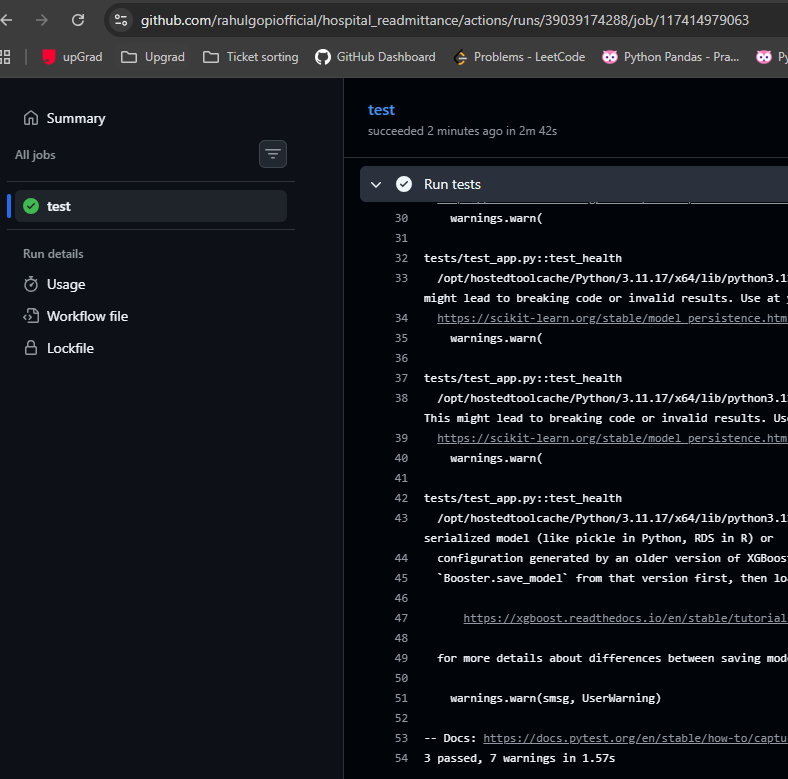

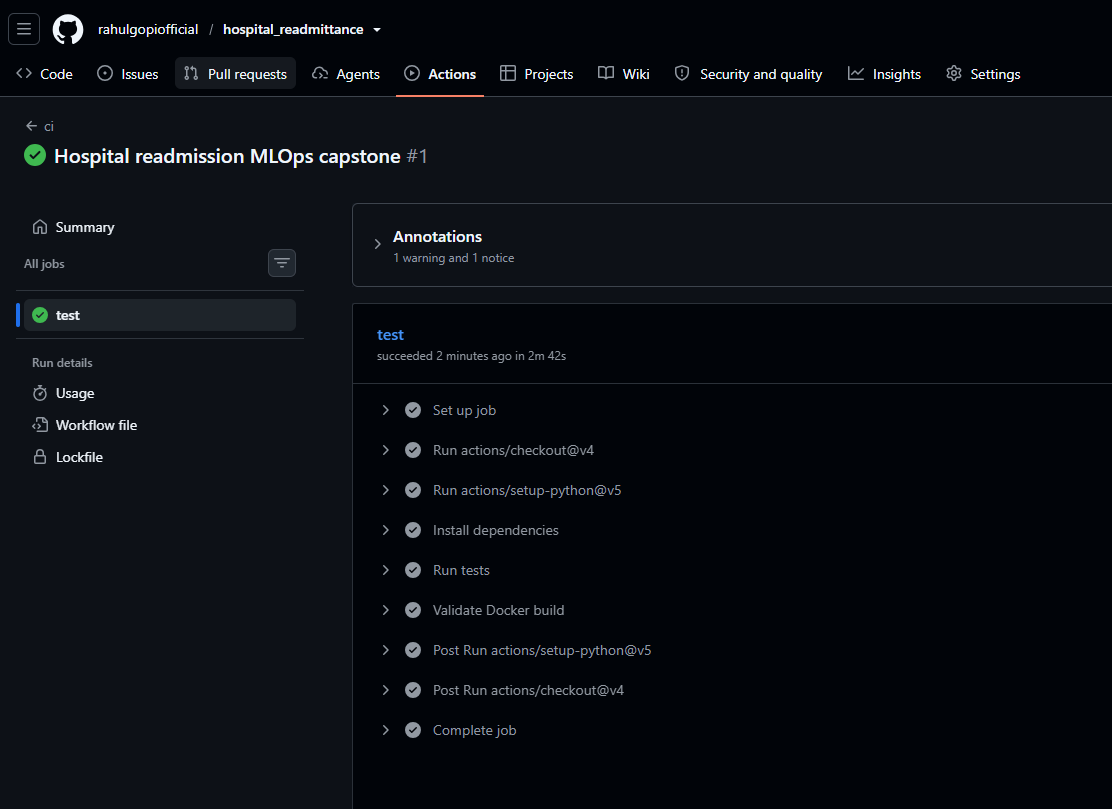

## Stage 4.4 — Monitoring & Drift Detection <font color="red">[4 marks]</font>

Implement `run_monitoring()` in `src/monitoring.py`.

- **4.4.1 — Feature drift (Evidently, reference vs current) [2]** — run an Evidently `DataDriftPreset` (reference vs current batch); summarise + visualise.
- **4.4.2 — Prediction drift (PSI on scores) + interpretation [2]** — compute PSI on model scores and interpret (prediction drift can exceed feature-level drift).

In [ ]:
# TODO 4.4.1: generate a current batch (src.generate_current_batch); run Evidently feature drift.
# TODO 4.4.2: compute prediction PSI on model scores; summarise, plot and interpret.

# import importlib
# import src.monitoring as monitoring

# import warnings
# warnings.simplefilter("ignore")

# print("Using:", monitoring.__file__)
# importlib.reload(monitoring)

# summary = monitoring.run_monitoring()
# print(summary)



import importlib
import json
import matplotlib.pyplot as plt
from src import generate_current_batch, monitoring
importlib.reload(monitoring)

import warnings
warnings.simplefilter("ignore")

# 4.4.1 - simulate a production batch with injected drift, then Evidently drift (reference vs current)
generate_current_batch.main()
summary = monitoring.run_monitoring()
print(json.dumps(summary, indent=2))

# 4.4.2 - prediction drift: PSI on model scores + score distributions
_, _, ref_scores, cur_scores = monitoring.load_scored_batches()
plt.hist(ref_scores, bins=40, range=(0, 1), alpha=0.6, label="reference")
plt.hist(cur_scores, bins=40, range=(0, 1), alpha=0.6, label="current")
plt.xlim(0, 1)
plt.xlabel("Predicted readmission probability")
plt.ylabel("Number of encounters")
plt.title(f"Prediction drift - PSI = {summary['prediction_psi']:.3f}")
plt.legend()
plt.tight_layout()
plt.show()

## Stage 4.5 — Retraining Workflow <font color="red">[3 marks]</font>

Implement the trigger + workflow in `src/retrain.py`.

- **4.5.1 — Multi-signal retraining trigger defined [1]** — prediction PSI > 0.2 OR drifted share > 0.3 OR dataset drift.
- **4.5.2 — Retraining workflow runs + re-registers + decision record [2]** — on a trigger, retrain + register a new version and record the decision (`retraining_decision.json`).

In [ ]:
# TODO 4.5.1: define the multi-signal trigger.
# TODO 4.5.2: on a trigger, retrain + register a new version; show the decision record.

import importlib
import src.retrain as retrain
import warnings
warnings.simplefilter("ignore")

importlib.reload(retrain)
decision = retrain.run_retraining_workflow()
print(decision)

In [ ]:
print(decision)

## Stage 4.6 — Logging & Governance <font color="red">[4 marks]</font>

- **4.6.1 — Prediction logging [2]** — show the `predictions.log` tail (proof predictions are logged).
- **4.6.2 — Model governance (registry history + alias + pinned deps) [2]** — show the MLflow registry version history + the `production` alias + pinned `requirements.txt`.

In [ ]:
%pip install "SQLAlchemy<2.1"

In [ ]:
# TODO 4.6.1: show the predictions.log tail.
# TODO 4.6.2: show the MLflow registry version history + production alias (governance).

import sqlite3
from pathlib import Path
import config as cfg

log_path = cfg.ARTIFACT_DIR / "predictions.log"

if not log_path.exists():
    raise FileNotFoundError(f"Prediction log not found: {log_path}")

lines = log_path.read_text(encoding="utf-8").splitlines()

print(f"Last {min(10, len(lines))} entries from {log_path}:")
for line in lines[-10:]:
    print(line)

print("\n\n")

db_path = Path("mlflow.db").resolve()
connection = sqlite3.connect(
    f"file:{db_path.as_posix()}?mode=ro",
    uri=True,
)
connection.row_factory = sqlite3.Row

model_name = cfg.REGISTERED_MODEL

print(f"Versions for {model_name}:")
for row in connection.execute(
    """
    SELECT name, version, current_stage, status, run_id
    FROM model_versions
    WHERE name = ?
    ORDER BY version
    """,
    (model_name,),
):
    print(dict(row))

print("\nProduction alias:")
for row in connection.execute(
    """
    SELECT name, alias, version
    FROM registered_model_aliases
    WHERE name = ? AND alias = ?
    """,
    (model_name, "production"),
):
    print(dict(row))

connection.close()

print("\n\n")

requirements_path = Path("requirements.txt")
print(requirements_path.read_text(encoding="utf-8"))

### ✍️ Stage 4 summary
*TODO: summarise API, container/CI, monitoring, retraining and governance, and confirm all evidence is captured in this notebook + report.*

### Stage 4 summary

- **API:** The FastAPI service was exercised through `TestClient`. `GET /health` and `POST /predict` both returned HTTP 200, and prediction requests were logged.
- **Container and CI:** The Docker image build completed successfully. The local test suite passed: **3 passed**. The notebook includes the build and test output as evidence.
- **Monitoring:** Evidently reported **25 of 39 features drifted** and `dataset_drift: true`. Prediction-score PSI was **0.4369**, indicating a substantial score-distribution shift. Interpret these results cautiously: the reference sample contains only 10 rows.
- **Retraining:** The drift signals triggered the retraining workflow. It returned `Advanced_XGBoost` with ROC-AUC **0.626** and recorded the decision.
- **Governance:** The notebook displays recent prediction-log entries, the dependency pins, and the registry output. The displayed registry database shows model **version 1** with the `production` alias pointing to version 1.